<a href="https://colab.research.google.com/github/sergeydorof/neural_networks_labs/blob/main/lab4/nn_lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

data = pd.read_csv('bodyPerformance.csv')
data

,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B
...,...,...,...,...,...,...,...,...,...,...,...,...
13388,25.0,M,172.1,71.80,16.2,74.0,141.0,35.8,17.4,47.0,198.0,C
13389,21.0,M,179.7,63.90,12.1,74.0,128.0,33.0,1.1,48.0,167.0,D
13390,39.0,M,177.2,80.50,20.1,78.0,132.0,63.5,16.4,45.0,229.0,A
13391,64.0,F,146.1,57.70,40.4,68.0,121.0,19.3,9.2,0.0,75.0,D


Признаки:
- age - возраст
- gender - пол
- height_cm - рост в сантиметрах
- weight_kg - вес в кг
- body fat_% - процент жира
- diastolic - диастолическое артериальное давление (мин.)
- systolic - систолическое артериальное давление (мин.)
- gripForce - сила хвата
- sit and bend forward_cm - сесть и наклониться вперед в см
- sit-ups counts - количество приседаний
- broad jump_cm - прыжок в длину с места в см

Таргет:
 - class - от A (самый здоровый) до D (самый нездоровый)

In [2]:
import pandas as pd

# 1. Пропуски по столбцам (количество и доля в %)
missing_count = data.isna().sum()
missing_pct = (data.isna().mean() * 100).round(2)
missing_df = pd.DataFrame({
    'missing_count': missing_count,
    'missing_pct': missing_pct,
})
print('Пропуски по столбцам:')
print(missing_df[missing_df['missing_count'] > 0])

# Общее число строк с хотя бы одним пропуском
print('Строк с пропусками:', data.isna().any(axis=1).sum())

# 2. Полные дубликаты строк
dup_count = data.duplicated().sum()
print('Полных дубликатов строк:', dup_count)

# Посмотреть сами дубликаты (keep=False покажет и оригинал, и копии)
data[data.duplicated(keep=False)].sort_values(by=list(data.columns))

Пропуски по столбцам:
Empty DataFrame
Columns: [missing_count, missing_pct]
Index: []
Строк с пропусками: 0
Полных дубликатов строк: 1


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
8965,27.0,F,157.0,49.1,30.7,70.0,86.0,27.7,19.7,51.0,167.0,A
12473,27.0,F,157.0,49.1,30.7,70.0,86.0,27.7,19.7,51.0,167.0,A


In [3]:
data = data.drop_duplicates()

Посмотреть распределение классов

/tmp/ipykernel_406/44979250.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


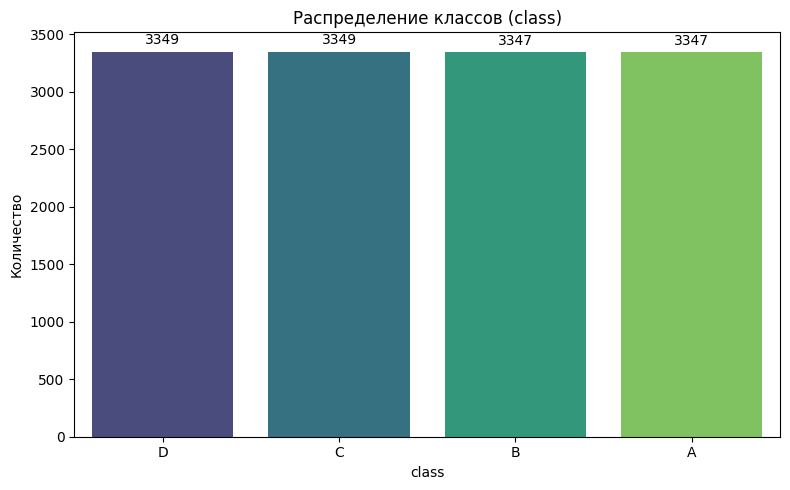

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

df = data  # или data, если меняли на месте
target_col = 'class'

# Опционально задать порядок классов на оси X:
class_order = ['D', 'C', 'B', 'A']

plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df,
    x=target_col,
    order=class_order,
    palette='viridis',
)

plt.title(f'Распределение классов ({target_col})')
plt.xlabel(target_col)
plt.ylabel('Количество')

for container in ax.containers:
  ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

Распределение классов по полу

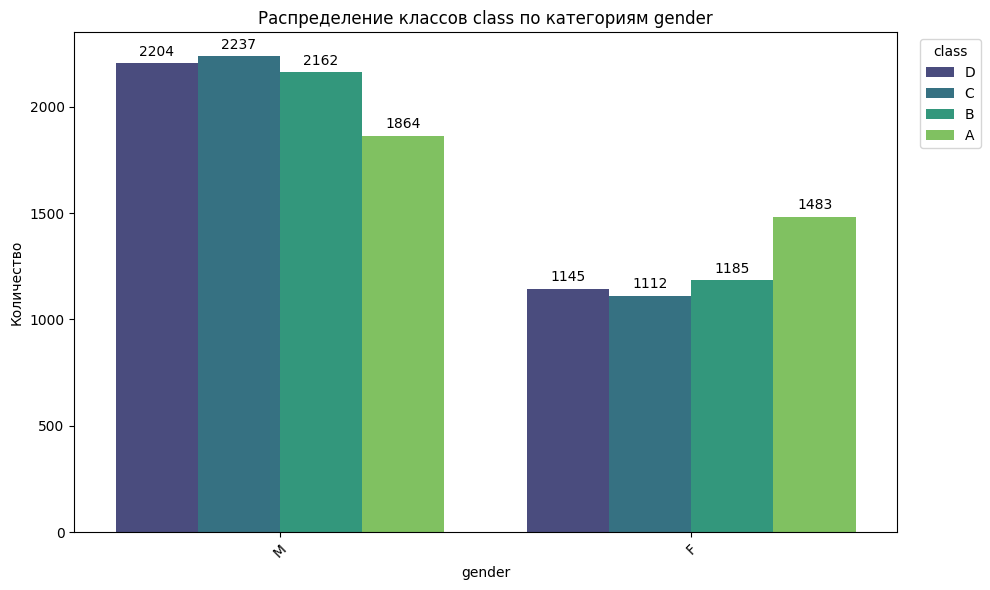

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

feature_col = 'gender'   # ось X (категории признака)
target_col = 'class'  # столбцы внутри каждой категории

feature_order = ['M', 'F']  # нужный порядок категорий признака на оси X
class_order = ['D', 'C', 'B', 'A']         # опционально: порядок столбцов внутри категории

plt.figure(figsize=(10, 6))
ax = sns.countplot(
    data=data,
    x=feature_col,
    hue=target_col,
    order=feature_order,
    hue_order=class_order,  # можно убрать, если порядок классов внутри группы не важен
    palette='viridis',
)

plt.title(f'Распределение классов {target_col} по категориям {feature_col}')
plt.xlabel(feature_col)
plt.ylabel('Количество')
plt.xticks(rotation=45)
plt.legend(title=target_col, bbox_to_anchor=(1.02, 1), loc='upper left')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

Оценка на выбросы с помощью ящиков с усами (сделаю ящики в диапазоне от 0.05% до 99.95%)

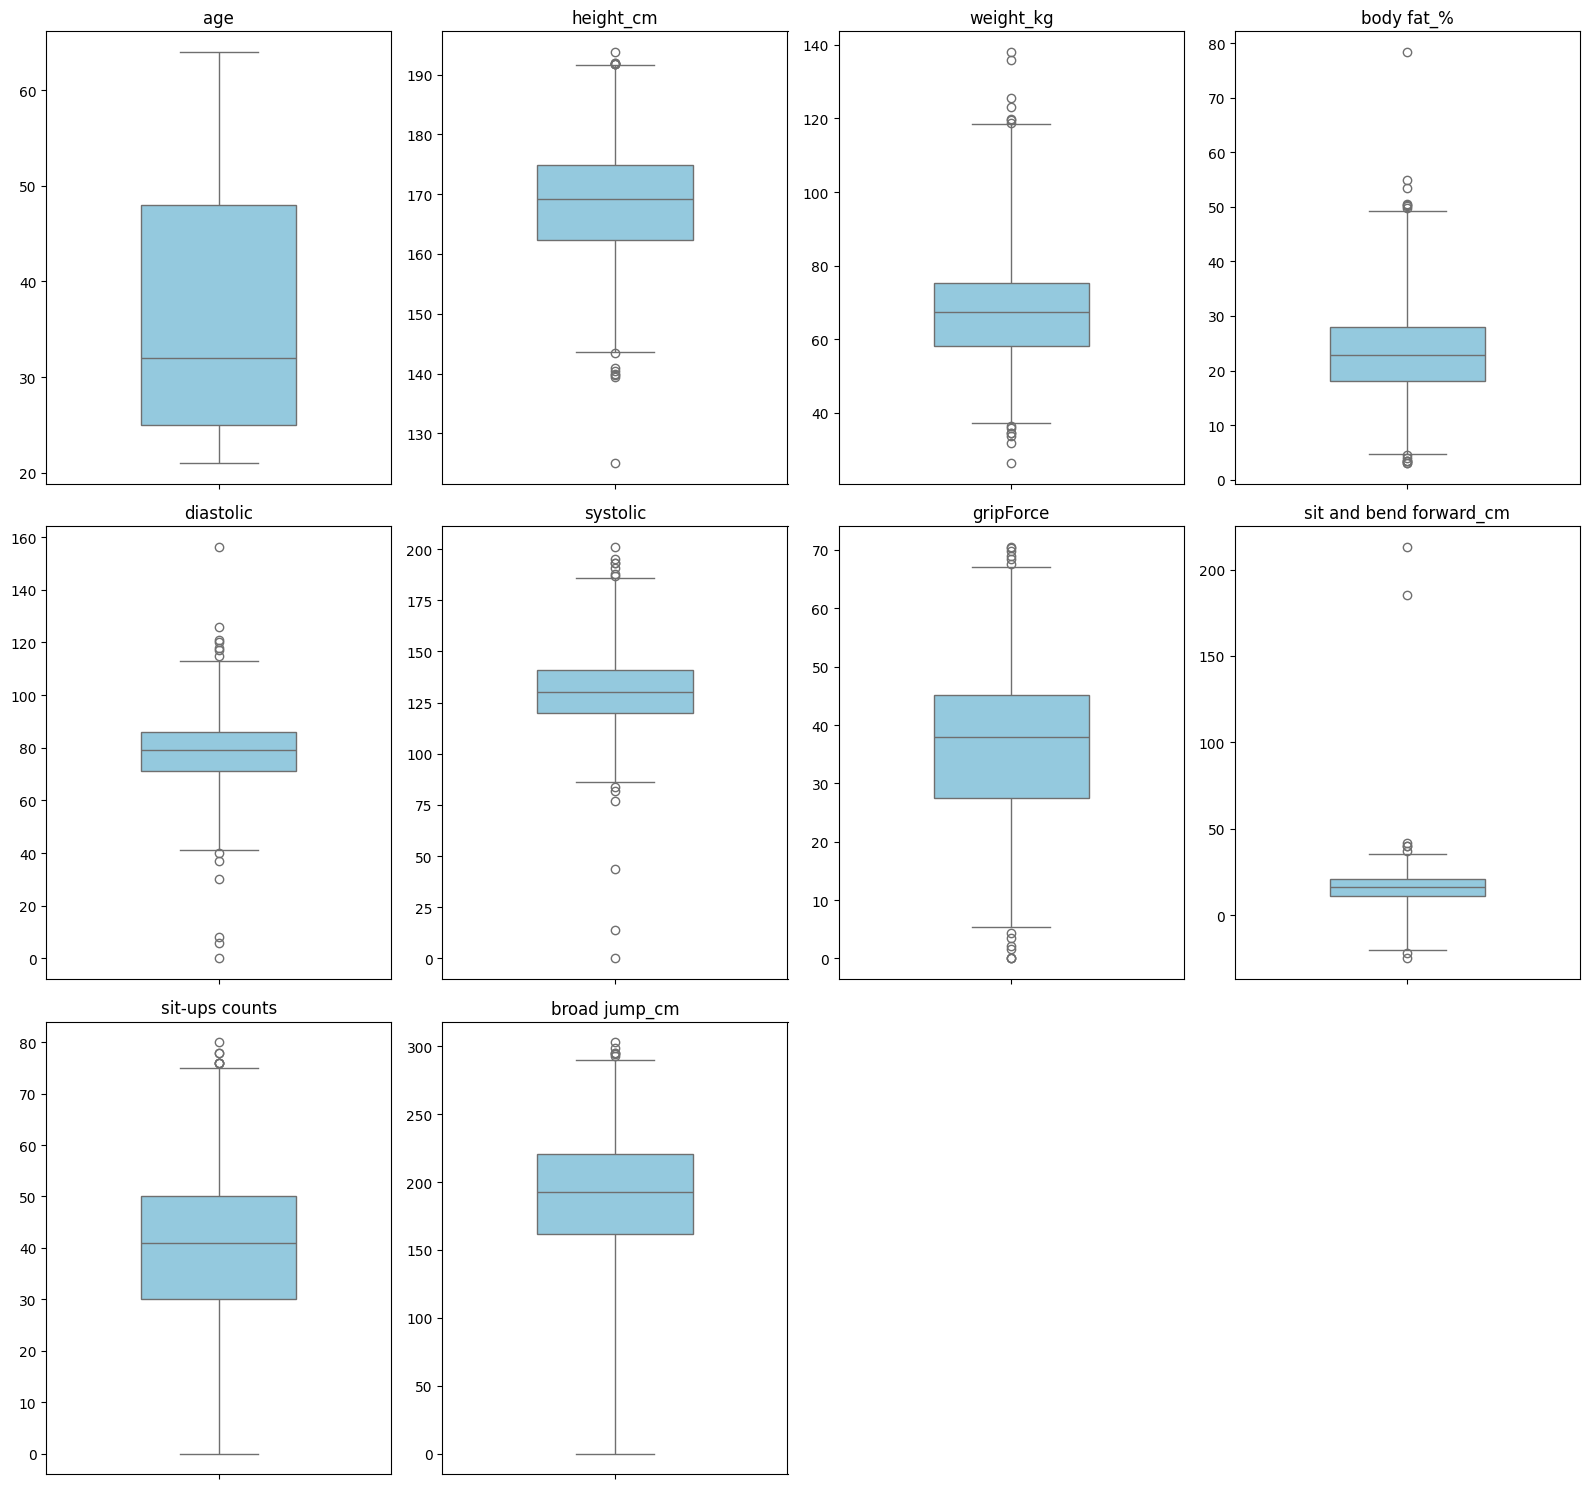

In [6]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

df = data  # или data, если меняли на месте

num_cols = df.select_dtypes(include='number').columns.tolist()

# Опционально исключаем служебные столбцы (ID, закодированный таргет и т.п.)
# exclude_cols = ['id', 'target']
# num_cols = [c for c in num_cols if c not in exclude_cols]

n_cols = 4  # для вертикальных боксплотов удобно брать 4–5 графиков в строке
n_rows = math.ceil(len(num_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 5 * n_rows))
axes = axes.flatten() if len(num_cols) > 1 else [axes]

for i, col in enumerate(num_cols):
  sns.boxplot(data=df, y=col, ax=axes[i], color='skyblue', width=0.45, whis=(0.05, 99.95))
  axes[i].set_title(col)
  axes[i].set_ylabel('')

for j in range(len(num_cols), len(axes)):
  axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [7]:
import pandas as pd

df = data  # или data, если меняли на месте
target_col = 'class'
cat_col = 'gender'

# Исключаем служебные столбцы, таргет и категориальный признак
ignore_cols = {target_col, cat_col}
num_cols = [
    c for c in df.select_dtypes(include='number').columns if c not in ignore_cols
]

mask = pd.Series(True, index=df.index)

for col in num_cols:
  low, high = df[col].quantile([0.0005, 0.9995])
  col_mask = df[col].isna() | ((df[col] >= low) & (df[col] <= high))
  removed = (~col_mask & mask).sum()
  print(f'{col}: [{low:.4g}, {high:.4g}] — новых удалений: {removed}')
  mask &= col_mask

df_clean_out = df[mask].reset_index(drop=True)
print(
    f'Было: {len(df)}, стало: {len(df_clean_out)}, удалено:'
    f' {len(df) - len(df_clean_out)}'
)
print(df_clean_out[target_col].value_counts())

age: [21, 64] — новых удалений: 0
height_cm: [143.5, 191.6] — новых удалений: 14
weight_kg: [37.06, 118.7] — новых удалений: 13
body fat_%: [4.639, 49.45] — новых удалений: 14
diastolic: [41, 113.6] — новых удалений: 13
systolic: [86, 186.3] — новых удалений: 10
gripForce: [5.026, 67.1] — новых удалений: 12
sit and bend forward_cm: [-20, 35.2] — новых удалений: 8
sit-ups counts: [0, 75.3] — новых удалений: 7
broad jump_cm: [0, 290] — новых удалений: 6
Было: 13392, стало: 13295, удалено: 97
class
C    3336
B    3327
A    3318
D    3314
Name: count, dtype: int64


Распределения числовых признаков

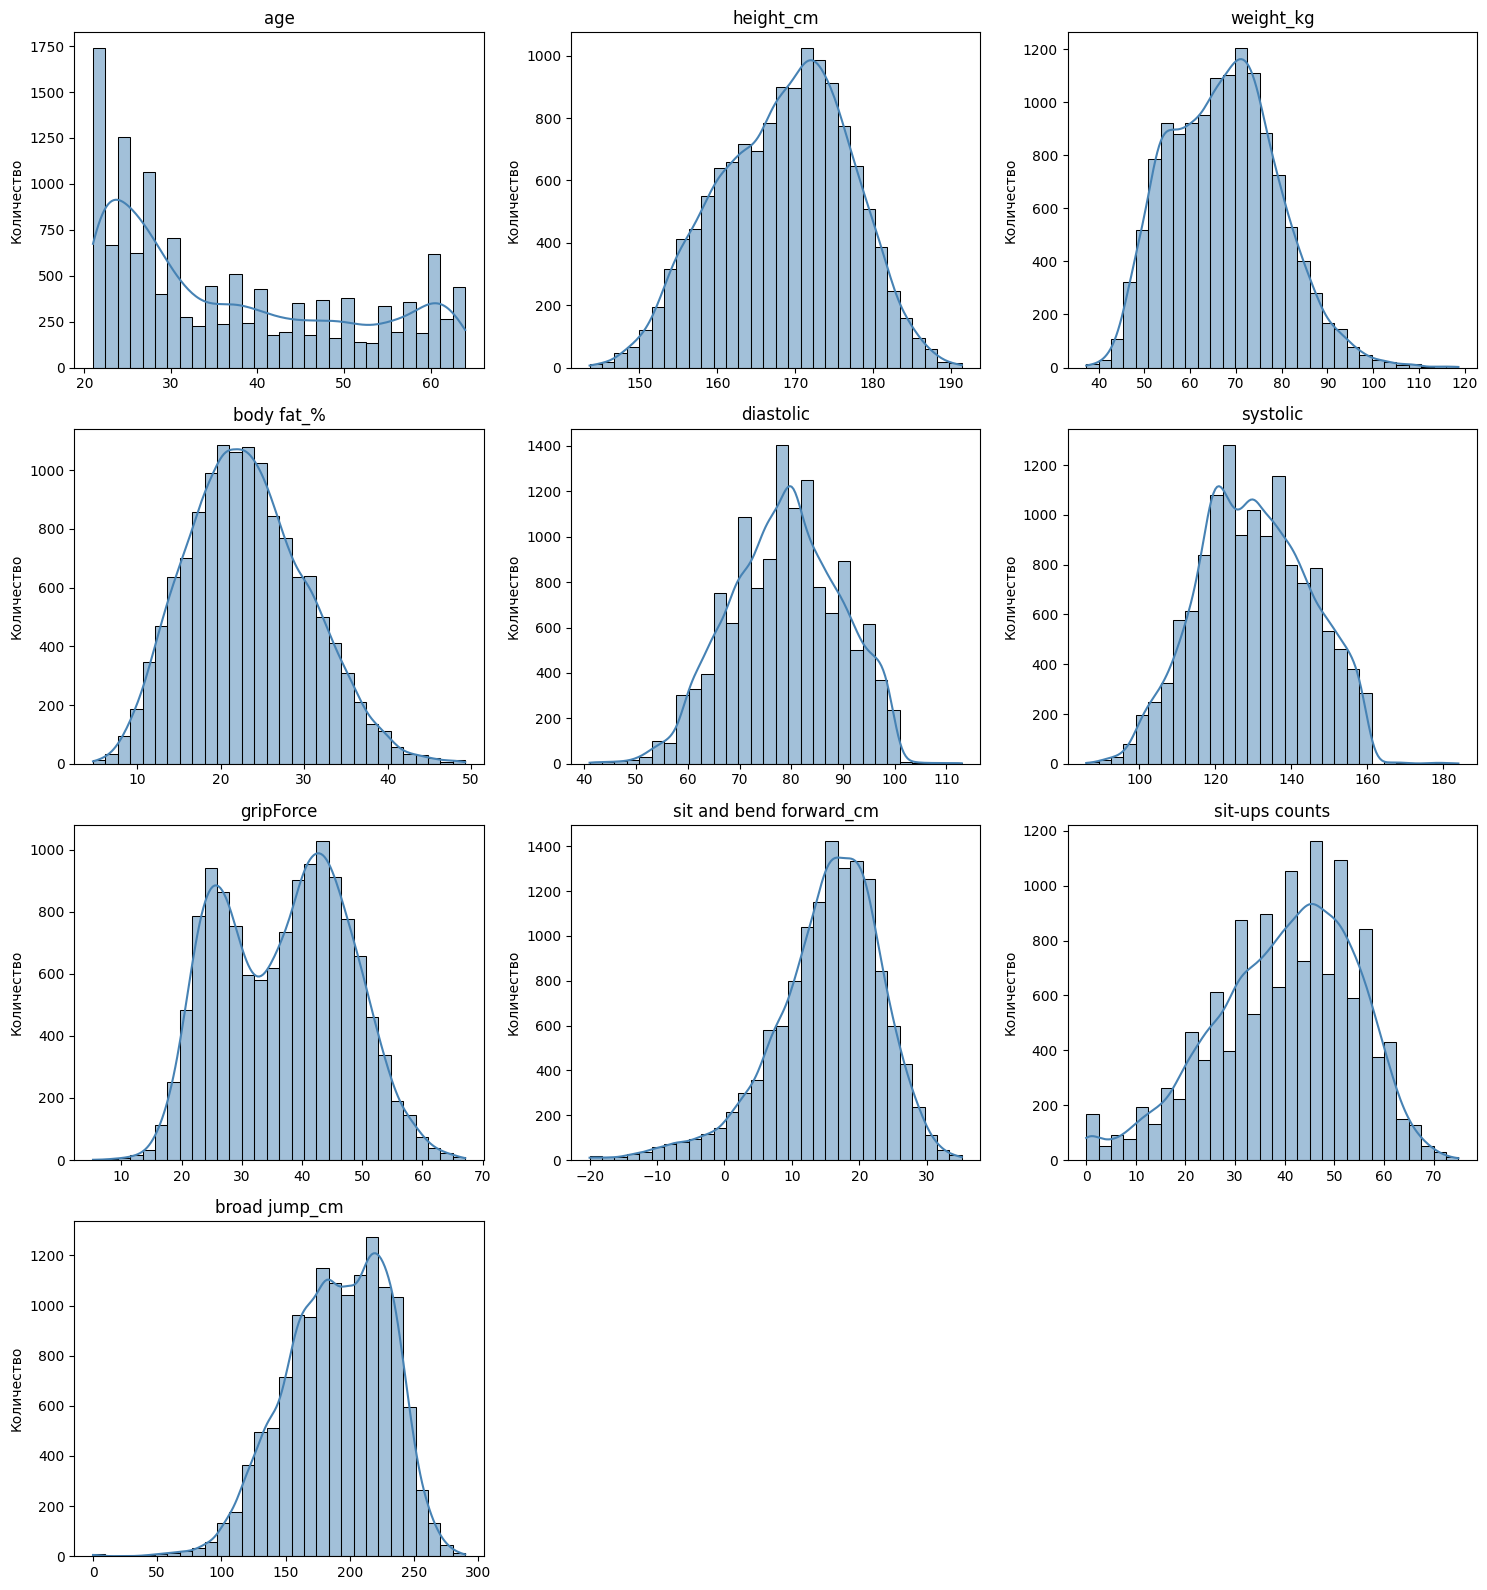

In [8]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

df = df_clean_out  # или df_clean / data

ignore_cols = {'gender', 'class'}  # при необходимости добавьте закодированный таргет
num_cols = [
    c for c in df.select_dtypes(include='number').columns if c not in ignore_cols
]

n_cols = 3
n_rows = math.ceil(len(num_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten() if len(num_cols) > 1 else [axes]

for i, col in enumerate(num_cols):
  sns.histplot(data=df, x=col, kde=True, bins=30, ax=axes[i], color='steelblue')
  axes[i].set_title(col)
  axes[i].set_xlabel('')
  axes[i].set_ylabel('Количество')

for j in range(len(num_cols), len(axes)):
  axes[j].set_visible(False)

plt.tight_layout()
plt.show()

Распределения по классам

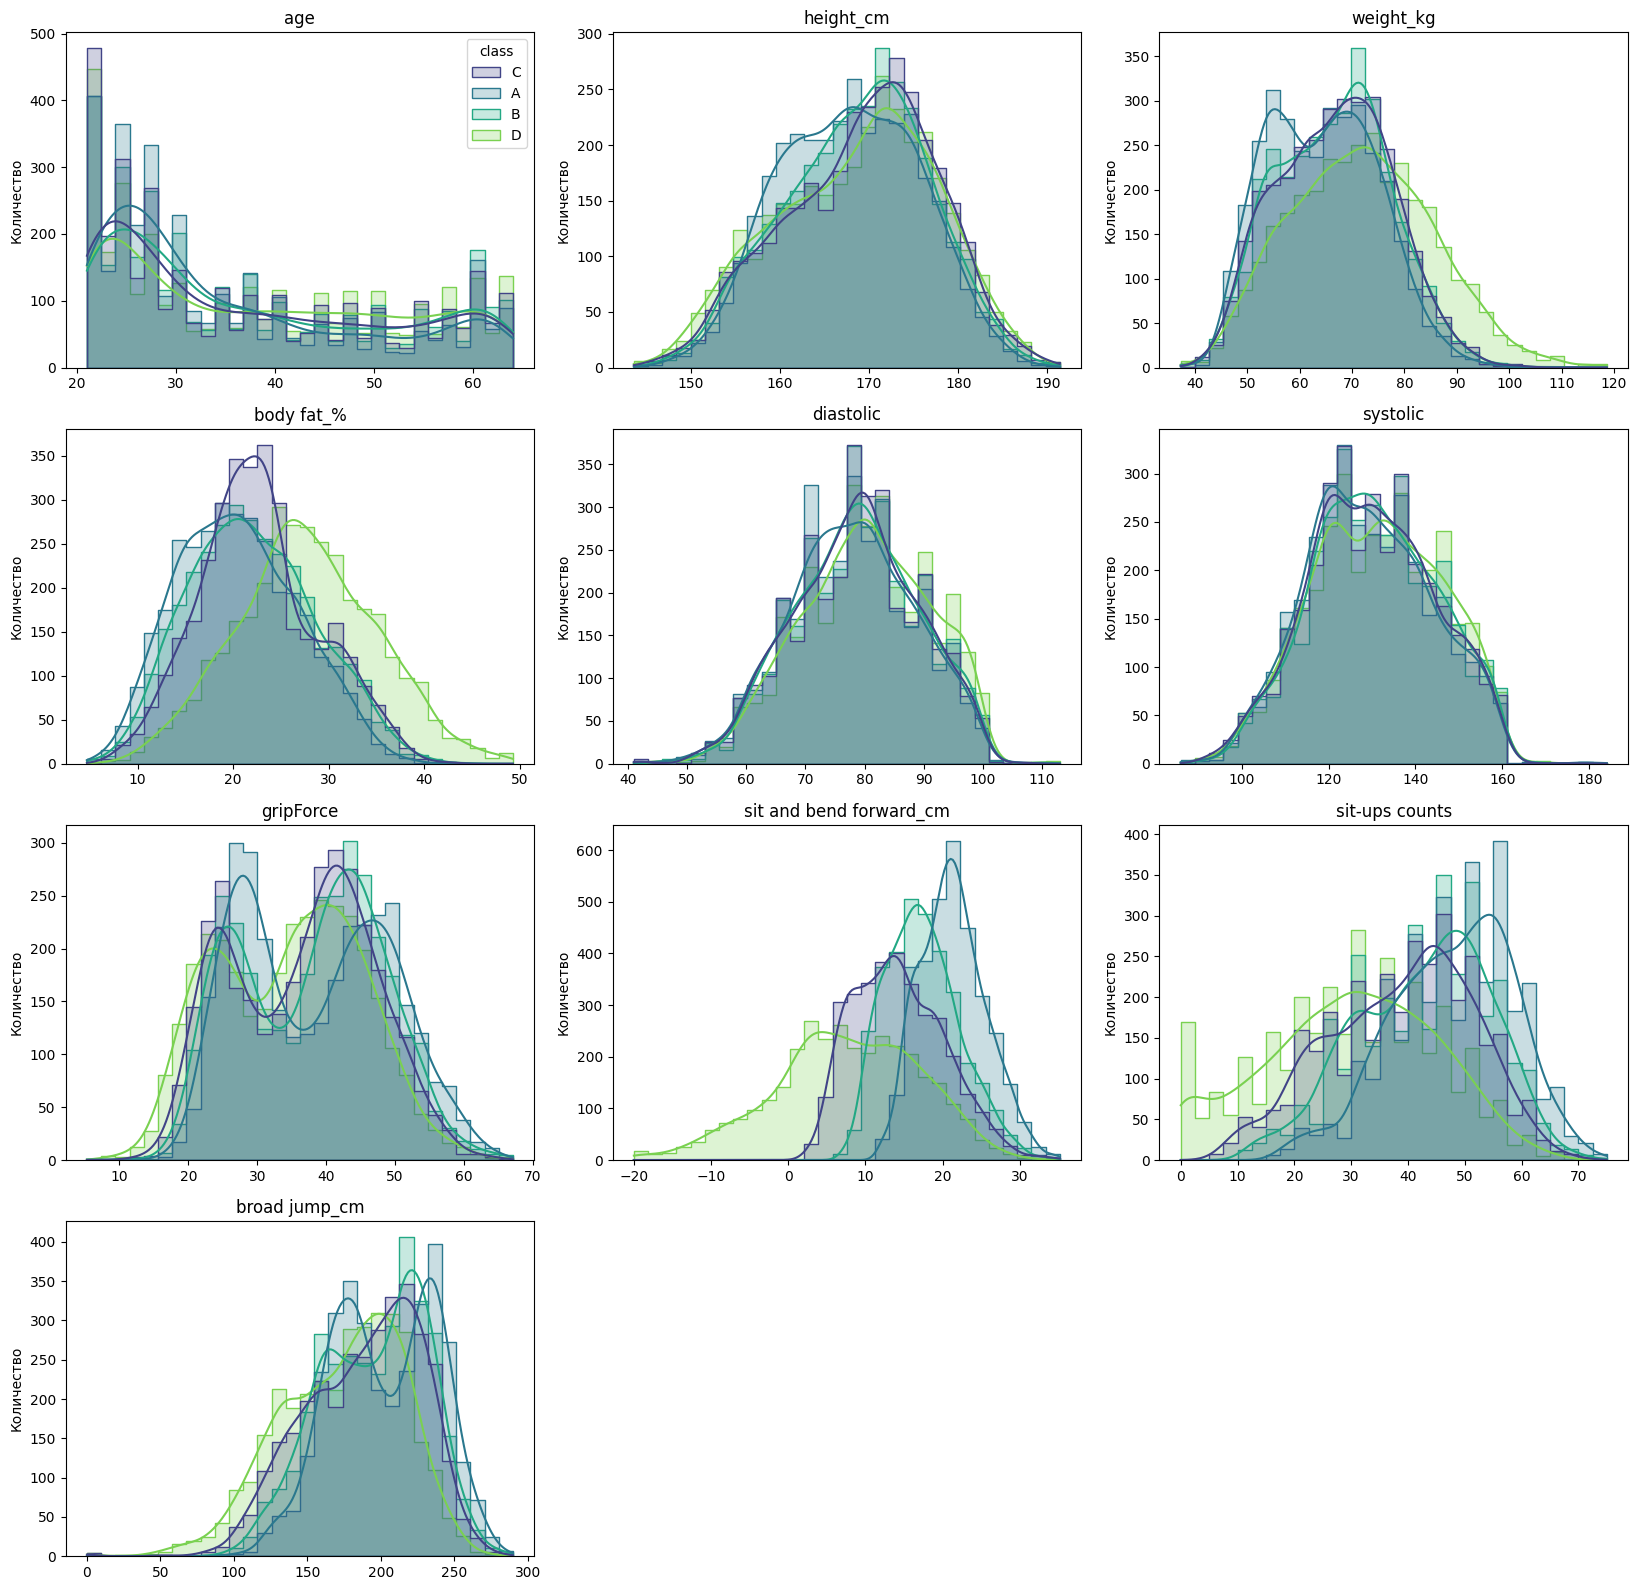

In [9]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

df = df_clean_out  # или df_clean / data
target_col = 'class'

ignore_cols = {'gender', target_col}
num_cols = [
    c for c in df.select_dtypes(include='number').columns if c not in ignore_cols
]

n_cols = 3
n_rows = math.ceil(len(num_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 4 * n_rows))
axes = axes.flatten() if len(num_cols) > 1 else [axes]

for i, col in enumerate(num_cols):
  sns.histplot(
      data=df,
      x=col,
      hue=target_col,
      kde=True,
      bins=30,
      element='step',       # контуры вместо перекрытия плотной заливкой
      common_norm=False,    # каждый класс нормируется отдельно (удобно для сравнения формы)
      palette='viridis',
      ax=axes[i],
  )
  axes[i].set_title(col)
  axes[i].set_xlabel('')
  axes[i].set_ylabel('Количество')

  # Оставляем легенду только на первом графике, чтобы не засорять сетку
  if i > 0 and axes[i].get_legend() is not None:
    axes[i].get_legend().remove()

for j in range(len(num_cols), len(axes)):
  axes[j].set_visible(False)

plt.tight_layout()
plt.show()

Матрица корреляций

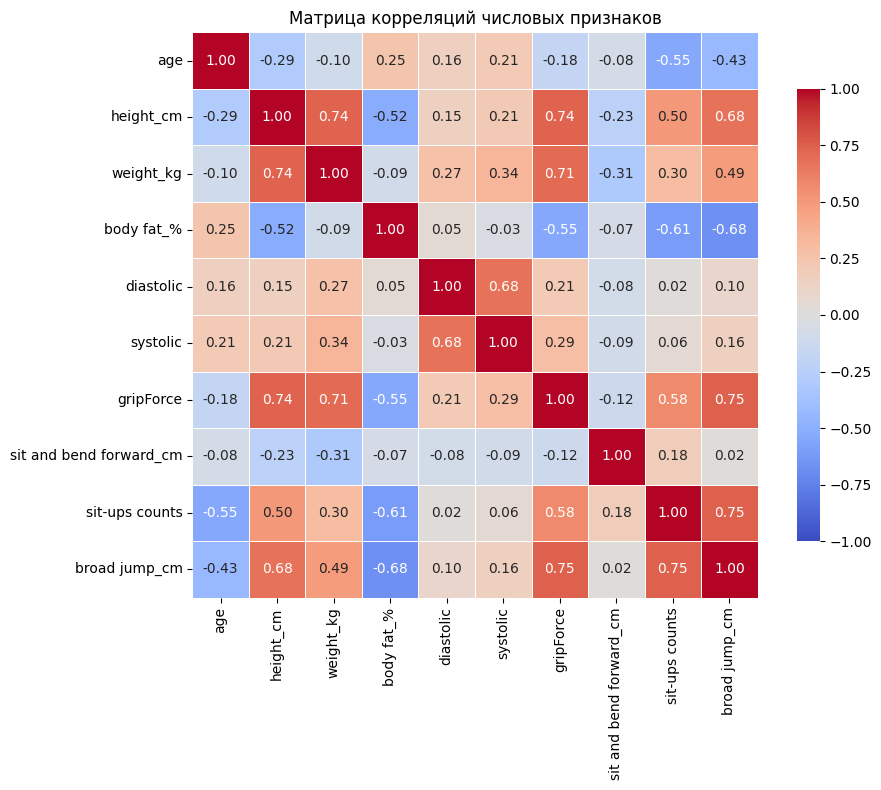

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

df = df_clean_out  # или df_clean / data

ignore_cols = {'gender'}  # при необходимости добавьте столбцы, которые не нужно включать
num_cols = [
    c for c in df.select_dtypes(include='number').columns if c not in ignore_cols
]

# method='pearson' (линейная связь) или 'spearman' (ранговая, лучше при асимметрии/нелинейности)
corr = df[num_cols].corr(method='pearson')

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,        # подписи коэффициентов в ячейках
    fmt='.2f',         # точность до сотых
    cmap='coolwarm',   # расходящаяся палитра: синий — минус, красный — плюс
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
)

plt.title('Матрица корреляций числовых признаков')
plt.tight_layout()
plt.show()

In [11]:
data = df_clean_out

Подготовка датафрейма для тестирования сжатия признакового пространства

In [12]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = data  # или df_clean / data
target_col = 'class'
cat_col = 'gender'

ignore_cols = {target_col, cat_col}
num_cols = [
    c for c in df.select_dtypes(include='number').columns if c not in ignore_cols
]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        (
            'cat',
            OneHotEncoder(sparse_output=False, handle_unknown='ignore'),
            [cat_col],
        ),
    ],
    remainder='drop',  # или 'passthrough', если нужно сохранить остальные столбцы
)

X_processed = preprocessor.fit_transform(df)
feature_names = preprocessor.get_feature_names_out()
df_encoded = pd.DataFrame(
    X_processed, columns=feature_names, index=df.index
)

# Если нужно вернуть целевую переменную обратно в датафрейм:
df_encoded[target_col] = df[target_col]

df_encoded

,num__age,num__height_cm,num__weight_kg,num__body fat_%,num__diastolic,num__systolic,num__gripForce,num__sit and bend forward_cm,num__sit-ups counts,num__broad jump_cm,cat__gender_F,cat__gender_M,class
0,-0.717450,0.447134,0.664135,-0.267800,0.113180,-0.015341,1.699885,0.395508,1.422717,0.678756,0.0,1.0,C
1,-0.864294,-0.424517,-0.982022,-1.046474,-0.169889,-0.290678,-0.052395,0.136772,0.930470,0.981491,0.0,1.0,A
2,-0.423761,1.318786,0.897848,-0.434658,1.245455,1.499016,0.743235,-0.393021,0.649186,-0.229450,0.0,1.0,C
3,-0.350339,0.709824,0.313564,-0.671042,-0.264245,1.154844,0.421195,0.001243,0.930470,0.729212,0.0,1.0,B
4,-0.644027,0.626241,0.025656,-0.851805,-0.830383,-0.221844,0.620102,1.467413,0.367902,0.678756,0.0,1.0,B
...,...,...,...,...,...,...,...,...,...,...,...,...,...
13290,-0.864294,0.423254,0.372840,-0.976949,-0.452958,0.741838,-0.109225,0.272300,0.508544,0.199425,0.0,1.0,C
13291,-1.157982,1.330726,-0.296123,-1.547050,-0.452958,-0.153010,-0.374435,-1.735983,0.578865,-0.582641,0.0,1.0,D
13292,0.163616,1.032216,1.109546,-0.434658,-0.075533,0.122328,2.514459,0.149092,0.367902,0.981491,0.0,1.0,A
13293,1.999170,-2.681259,-0.821132,2.388036,-1.019095,-0.634850,-1.672070,-0.738002,-2.796546,-2.903613,1.0,0.0,D


Сжатие + визуализация

Размер подвыборки: 5000
class
C    1255
B    1251
A    1248
D    1246
Name: count, dtype: int64
Считаю MDS...
Считаю Isomap...
Считаю LLE...
Считаю t-SNE...
Считаю UMAP...


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


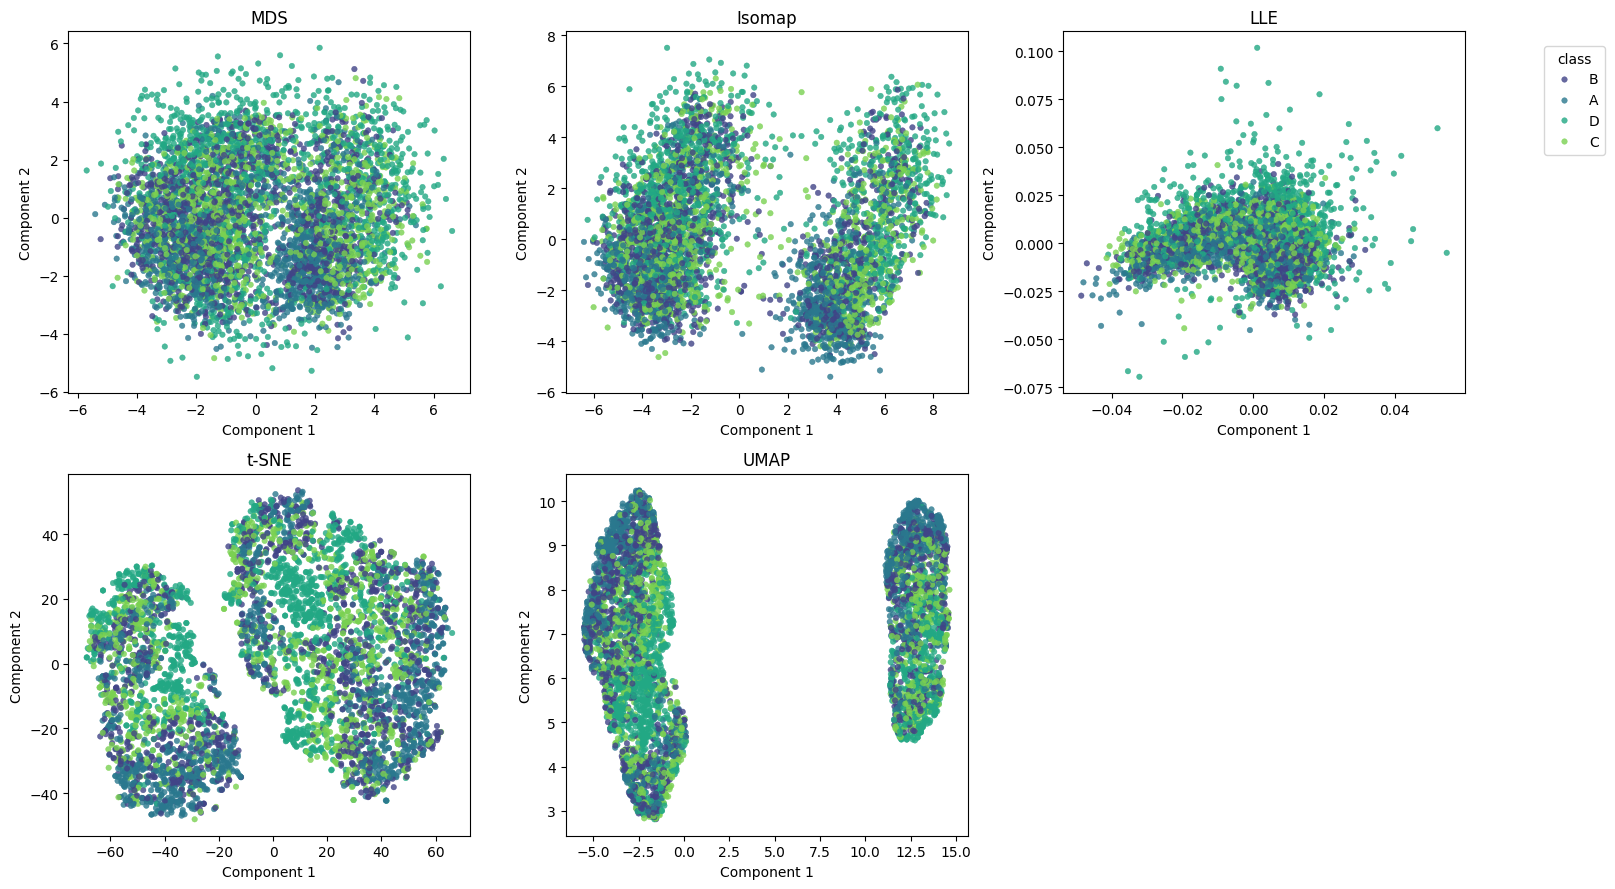

In [13]:
import math
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import Isomap, LocallyLinearEmbedding, MDS, TSNE
from sklearn.model_selection import train_test_split
import umap

target_col = 'class'
df_vis = df_encoded
X = df_vis.drop(columns=[target_col])
y = df_vis[target_col]

n_samples = min(5000, len(X))

# Случайная выборка со стратификацией по y — сохраняет равномерное распределение классов
if n_samples < len(X):
  _, X_sub, _, y_sub = train_test_split(
      X,
      y,
      test_size=n_samples,
      stratify=y,
      random_state=42,
  )
else:
  X_sub, y_sub = X, y

print('Размер подвыборки:', len(X_sub))
print(y_sub.value_counts())

methods = {
    'MDS': MDS(
        n_components=2,
        n_init=1,
        max_iter=200,
        random_state=42,
        n_jobs=1,
        normalized_stress='auto',
    ),
    'Isomap': Isomap(n_components=2, n_neighbors=15, n_jobs=-1),
    'LLE': LocallyLinearEmbedding(
        n_components=2, n_neighbors=15, random_state=42, n_jobs=-1
    ),
    't-SNE': TSNE(
        n_components=2, perplexity=30, init='pca', random_state=42, n_jobs=-1
    ),
    'UMAP': umap.UMAP(
        n_components=2, n_neighbors=15, min_dist=0.1, random_state=42
    ),
}

embeddings = {}
for name, reducer in methods.items():
  print(f'Считаю {name}...')
  embeddings[name] = reducer.fit_transform(X_sub)

n_cols = 3
n_rows = math.ceil(len(methods) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 4.5 * n_rows))
axes = axes.flatten()

for idx, (name, coords) in enumerate(embeddings.items()):
  sns.scatterplot(
      x=coords[:, 0],
      y=coords[:, 1],
      hue=y_sub,
      palette='viridis',
      s=16,
      alpha=0.8,
      edgecolor=None,
      ax=axes[idx],
  )
  axes[idx].set_title(name)
  axes[idx].set_xlabel('Component 1')
  axes[idx].set_ylabel('Component 2')
  if idx > 0 and axes[idx].get_legend() is not None:
    axes[idx].get_legend().remove()

handles, labels = axes[0].get_legend_handles_labels()
axes[0].get_legend().remove()
fig.legend(
    handles, labels, title=target_col, loc='upper right', bbox_to_anchor=(0.98, 0.95)
)

for j in range(len(methods), len(axes)):
  axes[j].set_visible(False)

plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()

Кластера оказалось 2 (кроме LLE - там 1) но классы перемешаны в этих кластерах

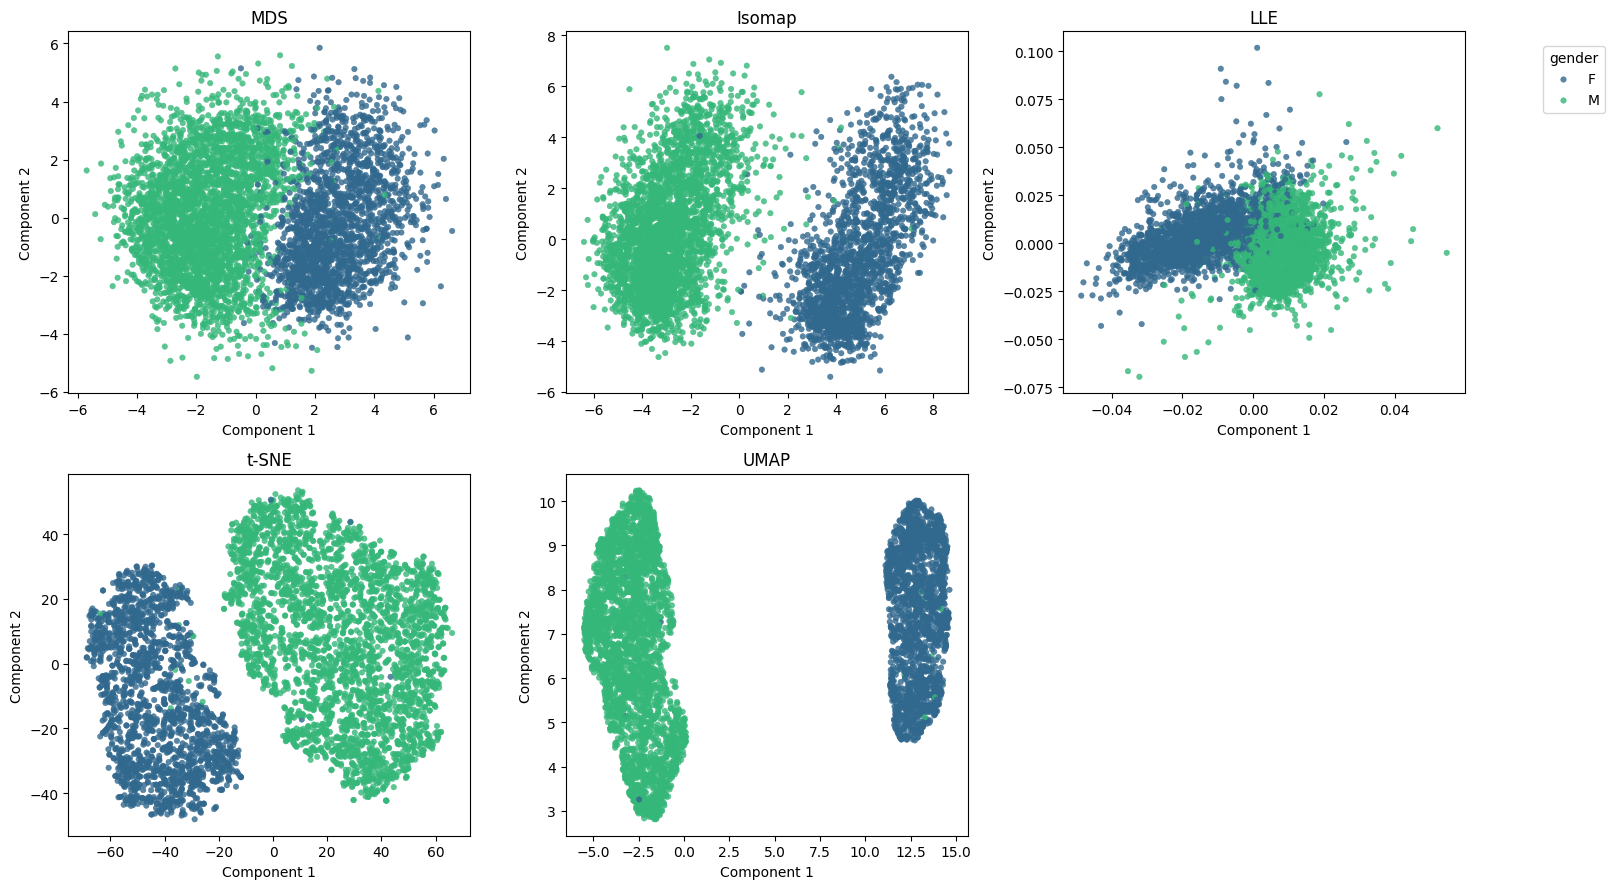

In [14]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

cat_col = 'gender'
color_labels = df_clean_out.loc[X_sub.index, cat_col]

n_cols = 3
n_rows = math.ceil(len(embeddings) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 4.5 * n_rows))
axes = axes.flatten()

for idx, (name, coords) in enumerate(embeddings.items()):
  sns.scatterplot(
      x=coords[:, 0],
      y=coords[:, 1],
      hue=color_labels,
      palette='viridis',
      s=16,
      alpha=0.8,
      edgecolor=None,
      ax=axes[idx],
  )
  axes[idx].set_title(name)
  axes[idx].set_xlabel('Component 1')
  axes[idx].set_ylabel('Component 2')
  if idx > 0 and axes[idx].get_legend() is not None:
    axes[idx].get_legend().remove()

handles, labels = axes[0].get_legend_handles_labels()
axes[0].get_legend().remove()
fig.legend(
    handles, labels, title=cat_col, loc='upper right', bbox_to_anchor=(0.98, 0.95)
)

for j in range(len(embeddings), len(axes)):
  axes[j].set_visible(False)

plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()

Оказалось кластеры образованы чисто различием по полу, но для каждого пола классы замешаны по-своему

In [15]:
from sklearn.manifold import Isomap, LocallyLinearEmbedding, MDS, TSNE
import umap

target_col = 'class'

methods_3d = {
    'MDS': MDS(
        n_components=3,
        n_init=1,
        max_iter=200,
        random_state=42,
        n_jobs=1,
        normalized_stress='auto',
    ),
    'Isomap': Isomap(n_components=3, n_neighbors=15, n_jobs=-1),
    'LLE': LocallyLinearEmbedding(
        n_components=3, n_neighbors=15, random_state=42, n_jobs=-1
    ),
    't-SNE': TSNE(
        n_components=3, perplexity=30, init='pca', random_state=42, n_jobs=-1
    ),
    'UMAP': umap.UMAP(
        n_components=3, n_neighbors=15, min_dist=0.1, random_state=42
    ),
}

# 1. Считаем 3D-проекции для всех методов
embeddings_3d = {}
for name, reducer in methods_3d.items():
  print(f'Считаю 3D {name}...')
  embeddings_3d[name] = reducer.fit_transform(X_sub)

Считаю 3D MDS...
Считаю 3D Isomap...
Считаю 3D LLE...
Считаю 3D t-SNE...
Считаю 3D UMAP...


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Функция для построения интерактивного графика

In [16]:
import plotly.express as px
import plotly.io as pio

pio.renderers.default = 'colab'


def plot_3d_interactive(
    method_name: str,
    embeddings_dict: dict = embeddings_3d,
    labels=y_sub,
    marker_size: int = 3,
    opacity: float = 0.75,
    height: int = 550,
):
  if method_name not in embeddings_dict:
    available = ', '.join(embeddings_dict.keys())
    raise ValueError(
        f"Неизвестный метод '{method_name}'. Доступные: {available}"
    )

  coords = embeddings_dict[method_name]
  fig = px.scatter_3d(
      x=coords[:, 0],
      y=coords[:, 1],
      z=coords[:, 2],
      color=labels.astype(str),
      labels={
          'x': 'Dim 1',
          'y': 'Dim 2',
          'z': 'Dim 3',
          'color': target_col,
      },
      title=f'{method_name} — 3D проекция',
      opacity=opacity,
  )
  fig.update_traces(marker=dict(size=marker_size))
  fig.update_layout(
      height=height,
      margin=dict(l=0, r=0, t=45, b=0),
      legend_title_text=target_col,
  )
  fig.show(renderer='colab')

In [ ]:
# Примеры вызова:
plot_3d_interactive('UMAP')
# plot_3d_interactive('t-SNE')
# plot_3d_interactive('Isomap')
# plot_3d_interactive('MDS')
# plot_3d_interactive('LLE')

In [ ]:
# Примеры вызова:
# plot_3d_interactive('UMAP')
plot_3d_interactive('t-SNE')
# plot_3d_interactive('Isomap')
# plot_3d_interactive('MDS')
# plot_3d_interactive('LLE')

In [ ]:
# Примеры вызова:
# plot_3d_interactive('UMAP')
# plot_3d_interactive('t-SNE')
plot_3d_interactive('Isomap')
# plot_3d_interactive('MDS')
# plot_3d_interactive('LLE')

In [ ]:
# Примеры вызова:
# plot_3d_interactive('UMAP')
# plot_3d_interactive('t-SNE')
# plot_3d_interactive('Isomap')
plot_3d_interactive('MDS')
# plot_3d_interactive('LLE')

In [ ]:
# Примеры вызова:
# plot_3d_interactive('UMAP')
# plot_3d_interactive('t-SNE')
# plot_3d_interactive('Isomap')
# plot_3d_interactive('MDS')
plot_3d_interactive('LLE')

Все равно классы сильно перемешаны но тут уже видна какая-никакая тенденция: образуется два кластера по половому признаку, но при этом, в отличие от 2-х компонент, тут в каждом из кластеров виден переход цветов от одного края - бирюзового (класс D) к другому, красному краю (класс A)

В целом улавливается идея: кластер мужчин и кластер женщин, в каждом из которых идет изменение физических показателей и соответствующее ему изменение класса здоровья от плохого к хорошему

Хотя и трех компонент тоже недостаточно чтобы качественно разделить тк классы все еще сильно перемешаны

Результаты KMeans по всем проекциям:
dim method      ARI      NMI  mean_score
 2D   UMAP 0.039191 0.047760    0.043475
 2D Isomap 0.033464 0.042412    0.037938
 2D  t-SNE 0.031969 0.038548    0.035259
 2D    MDS 0.029704 0.034410    0.032057
 2D    LLE 0.021638 0.034358    0.027998
 3D    MDS 0.049501 0.060255    0.054878
 3D   UMAP 0.045024 0.053462    0.049243
 3D Isomap 0.036982 0.048659    0.042821
 3D  t-SNE 0.032648 0.039939    0.036294
 3D    LLE 0.006440 0.007637    0.007038

Лучший 2D: UMAP (ARI=0.0392, NMI=0.0478)
Лучший 3D: MDS (ARI=0.0495, NMI=0.0603)


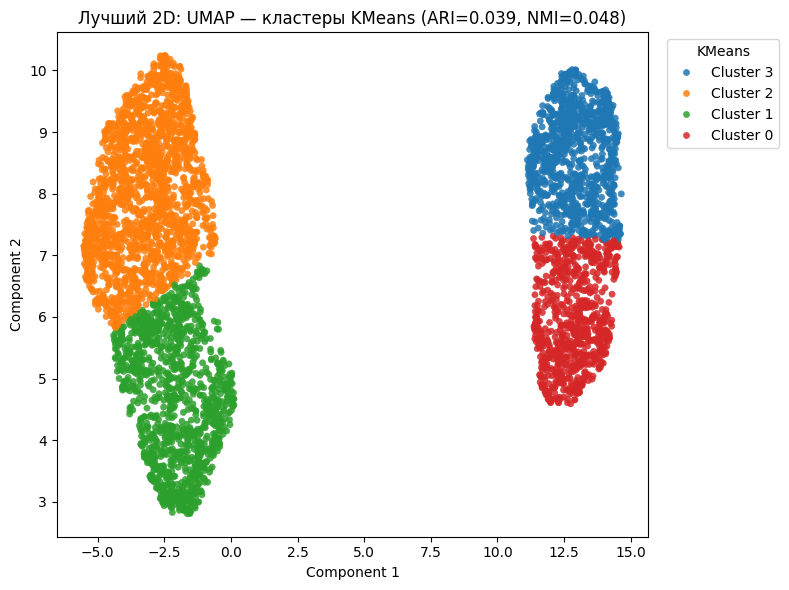

In [17]:
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

pio.renderers.default = 'colab'

# Число кластеров берём равным числу уникальных классов в y_sub
n_clusters = y_sub.nunique()

# Единые гиперпараметры KMeans для всех пространств
kmeans_params = {
    'n_clusters': n_clusters,
    'n_init': 20,
    'max_iter': 300,
    'random_state': 42,
}

results = []
kmeans_labels = {'2D': {}, '3D': {}}

spaces = {
    '2D': embeddings,
    '3D': embeddings_3d,
}

for dim_name, space_dict in spaces.items():
  for method_name, coords in space_dict.items():
    km = KMeans(**kmeans_params)
    cluster_pred = km.fit_predict(coords)
    kmeans_labels[dim_name][method_name] = cluster_pred

    # ARI и NMI не зависят от перестановок имён кластеров и работают со строковыми метками ('А', 'В', ...)
    ari = adjusted_rand_score(y_sub, cluster_pred)
    nmi = normalized_mutual_info_score(y_sub, cluster_pred)

    results.append({
        'dim': dim_name,
        'method': method_name,
        'ARI': ari,
        'NMI': nmi,
        'mean_score': (ari + nmi) / 2,
    })

metrics_df = pd.DataFrame(results).sort_values(
    by=['dim', 'ARI', 'NMI'], ascending=[True, False, False]
)
print('Результаты KMeans по всем проекциям:')
print(metrics_df.to_string(index=False))

# Выбор лучшего метода для 2D и 3D (по ARI, при равенстве — по NMI)
best_2d_row = (
    metrics_df[metrics_df['dim'] == '2D']
    .sort_values(by=['ARI', 'NMI'], ascending=False)
    .iloc[0]
)
best_3d_row = (
    metrics_df[metrics_df['dim'] == '3D']
    .sort_values(by=['ARI', 'NMI'], ascending=False)
    .iloc[0]
)

best_2d_method = best_2d_row['method']
best_3d_method = best_3d_row['method']

print(
    f"\nЛучший 2D: {best_2d_method} "
    f"(ARI={best_2d_row['ARI']:.4f}, NMI={best_2d_row['NMI']:.4f})"
)
print(
    f"Лучший 3D: {best_3d_method} "
    f"(ARI={best_3d_row['ARI']:.4f}, NMI={best_3d_row['NMI']:.4f})"
)

# 1. График лучшего 2D-пространства с цветами от KMeans
coords_2d = embeddings[best_2d_method]
clusters_2d = [f'Cluster {c}' for c in kmeans_labels['2D'][best_2d_method]]

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=coords_2d[:, 0],
    y=coords_2d[:, 1],
    hue=clusters_2d,
    palette='tab10',
    s=20,
    alpha=0.85,
    edgecolor=None,
)
plt.title(
    f'Лучший 2D: {best_2d_method} — кластеры KMeans '
    f"(ARI={best_2d_row['ARI']:.3f}, NMI={best_2d_row['NMI']:.3f})"
)
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.legend(title='KMeans', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 2. Интерактивный 3D-график лучшего 3D-пространства с цветами от KMeans
coords_3d = embeddings_3d[best_3d_method]
clusters_3d = [f'Cluster {c}' for c in kmeans_labels['3D'][best_3d_method]]

fig_3d = px.scatter_3d(
    x=coords_3d[:, 0],
    y=coords_3d[:, 1],
    z=coords_3d[:, 2],
    color=clusters_3d,
    labels={'x': 'Dim 1', 'y': 'Dim 2', 'z': 'Dim 3', 'color': 'KMeans'},
    title=(
        f'Лучший 3D: {best_3d_method} — кластеры KMeans '
        f"(ARI={best_3d_row['ARI']:.3f}, NMI={best_3d_row['NMI']:.3f})"
    ),
    opacity=0.8,
)
fig_3d.update_traces(marker=dict(size=3))
fig_3d.update_layout(
    height=550,
    margin=dict(l=0, r=0, t=45, b=0),
    legend_title_text='KMeans',
)
fig_3d.show(renderer='colab')

ожидаемо, k-means не справился нигде. везде результат - случайное угадывание. что неудивительно учитывая что было замечено на графиках

Теперь надо используя обученные модели ISOMAP, LLE, UMAP по новой трансормировать признаковое пространство и обучить и проверить на них решающее дерево и случайный лес

In [20]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

df_base = df_clean_out
target_col = 'class'
cat_col = 'gender'
ignore_cols = {'id', target_col, cat_col}

num_cols = [
    c
    for c in df_base.select_dtypes(include='number').columns
    if c not in ignore_cols
]

label_map = {'D': 0, 'C': 1, 'B': 2, 'A': 3}
target_names = ['D', 'C', 'B', 'A']
y_encoded = df_base[target_col].map(label_map)
X_raw = df_base.drop(columns=[target_col])

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y_encoded,
    test_size=0.2,
    stratify=y_encoded,
    random_state=42,
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        (
            'cat',
            OneHotEncoder(sparse_output=False, handle_unknown='ignore'),
            [cat_col],
        ),
    ],
    remainder='drop',
)

X_train_proc = preprocessor.fit_transform(X_train_raw)
X_test_proc = preprocessor.transform(X_test_raw)

# Берём уже обученные ранее объекты редукторов (из reducers_2d или methods)
fitted_transform_models = {
    name: reducer
    for name, reducer in methods.items()  # или methods
    if name in {'Isomap', 'LLE', 'UMAP'}
}

cls_models = {
    'DecisionTree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'RandomForest': RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
}

eval_rows = []

for space_name, reducer in fitted_transform_models.items():
  # Только .transform() — без переобучения редуктора
  X_tr_2d = reducer.transform(X_train_proc)
  X_te_2d = reducer.transform(X_test_proc)

  for model_name, base_clf in cls_models.items():
    clf = type(base_clf)(**base_clf.get_params())
    clf.fit(X_tr_2d, y_train)
    y_pred = clf.predict(X_te_2d)

    eval_rows.append({
        'space_2d': space_name,
        'model': model_name,
        'accuracy': accuracy_score(y_test, y_pred),
        'f1_macro': f1_score(y_test, y_pred, average='macro'),
        'f1_weighted': f1_score(y_test, y_pred, average='weighted'),
    })

    print(f'\n=== [Уже обученный transform] {space_name} + {model_name} ===')
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1, 2, 3],
            target_names=target_names,
            digits=4,
            zero_division=0,
        )
    )

results_cls_df = pd.DataFrame(eval_rows).sort_values(
    by=['f1_macro', 'accuracy'], ascending=False
)
print('\nСводка качества на тесте:')
print(results_cls_df.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but NearestNeighbors was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but NearestNeighbors was fitted with feature names




=== [Уже обученный transform] Isomap + DecisionTree ===
              precision    recall  f1-score   support

           D     0.4405    0.4857    0.4620       663
           C     0.3007    0.4048    0.3450       667
           B     0.2416    0.0977    0.1392       665
           A     0.4507    0.5166    0.4814       664

    accuracy                         0.3761      2659
   macro avg     0.3584    0.3762    0.3569      2659
weighted avg     0.3582    0.3761    0.3568      2659


=== [Уже обученный transform] Isomap + RandomForest ===
              precision    recall  f1-score   support

           D     0.4039    0.4344    0.4186       663
           C     0.2681    0.2549    0.2613       667
           B     0.2442    0.2391    0.2416       665
           A     0.3949    0.3931    0.3940       664

    accuracy                         0.3302      2659
   macro avg     0.3278    0.3304    0.3289      2659
weighted avg     0.3277    0.3302    0.3287      2659



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LocallyLinearEmbedding was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LocallyLinearEmbedding was fitted with feature names




=== [Уже обученный transform] LLE + DecisionTree ===
              precision    recall  f1-score   support

           D     0.5264    0.4661    0.4944       663
           C     0.2886    0.2384    0.2611       667
           B     0.3159    0.4090    0.3565       665
           A     0.3697    0.3675    0.3686       664

    accuracy                         0.3701      2659
   macro avg     0.3751    0.3702    0.3701      2659
weighted avg     0.3750    0.3701    0.3700      2659


=== [Уже обученный transform] LLE + RandomForest ===
              precision    recall  f1-score   support

           D     0.4418    0.4465    0.4441       663
           C     0.2730    0.2669    0.2699       667
           B     0.2716    0.2692    0.2704       665
           A     0.3304    0.3373    0.3338       664

    accuracy                         0.3298      2659
   macro avg     0.3292    0.3300    0.3296      2659
weighted avg     0.3291    0.3298    0.3294      2659


=== [Уже обученный tr

Видно что у моделей низкая точность, однако для пространства, сжатого с помощью UMAP accuracy а также f1 macro показали результат около 0.46 что лучше случайного угадывания с учетом того что классов 4 (в таком случае при случайном угадывании accuracy должна была бы быть где-то около 0.25)

Теперь эксперимент с t-SNE и MDS (так как у них нет transform)

In [21]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

label_map = {'D': 0, 'C': 1, 'B': 2, 'A': 3}
target_names = ['D', 'C', 'B', 'A']
y_5k = y_sub.map(label_map) if y_sub.isin(label_map.keys()).all() else y_sub

# Используем уже готовые координаты на 5000 строк
precomputed_no_transform = {
    'MDS': embeddings['MDS'],
    't-SNE': embeddings['t-SNE'],
}

cls_models = {
    'DecisionTree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'RandomForest': RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
}

rows = []

for space_name, coords_2d in precomputed_no_transform.items():
  X_tr, X_te, y_tr, y_te = train_test_split(
      coords_2d,
      y_5k,
      test_size=0.2,
      stratify=y_5k,
      random_state=42,
  )

  for model_name, base_clf in cls_models.items():
    clf = type(base_clf)(**base_clf.get_params())
    clf.fit(X_tr, y_tr)
    y_pred = clf.predict(X_te)

    rows.append({
        'space_2d': space_name,
        'model': model_name,
        'accuracy': accuracy_score(y_te, y_pred),
        'f1_macro': f1_score(y_te, y_pred, average='macro'),
        'f1_weighted': f1_score(y_te, y_pred, average='weighted'),
    })

    print(f'\n=== [Готовые координаты без transform] {space_name} + {model_name} ===')
    print(
        classification_report(
            y_te,
            y_pred,
            labels=[0, 1, 2, 3],
            target_names=target_names,
            digits=4,
            zero_division=0,
        )
    )

no_transform_results_df = pd.DataFrame(rows).sort_values(
    by=['f1_macro', 'accuracy'], ascending=False
)
print('\nСводка качества на тесте (готовые 2D-координаты без transform):')
print(no_transform_results_df.to_string(index=False))


=== [Готовые координаты без transform] MDS + DecisionTree ===
              precision    recall  f1-score   support

           D     0.4720    0.4739    0.4729       249
           C     0.2614    0.1594    0.1980       251
           B     0.2761    0.3600    0.3125       250
           A     0.4354    0.4720    0.4530       250

    accuracy                         0.3660      1000
   macro avg     0.3612    0.3663    0.3591      1000
weighted avg     0.3610    0.3660    0.3588      1000


=== [Готовые координаты без transform] MDS + RandomForest ===
              precision    recall  f1-score   support

           D     0.4373    0.4618    0.4492       249
           C     0.2510    0.2470    0.2490       251
           B     0.2375    0.2280    0.2327       250
           A     0.3760    0.3760    0.3760       250

    accuracy                         0.3280      1000
   macro avg     0.3254    0.3282    0.3267      1000
weighted avg     0.3253    0.3280    0.3265      1000


===

Результат примерно тот же

Для интереса проделаем все то же самое, но с 3D (ведь помним что 3D графики были куда информативнее)

In [22]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

df_base = df_clean_out
target_col = 'class'
cat_col = 'gender'
ignore_cols = {'id', target_col, cat_col}

num_cols = [
    c
    for c in df_base.select_dtypes(include='number').columns
    if c not in ignore_cols
]

label_map = {'D': 0, 'C': 1, 'B': 2, 'A': 3}
target_names = ['D', 'C', 'B', 'A']
y_encoded = df_base[target_col].map(label_map)
X_raw = df_base.drop(columns=[target_col])

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y_encoded,
    test_size=0.2,
    stratify=y_encoded,
    random_state=42,
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        (
            'cat',
            OneHotEncoder(sparse_output=False, handle_unknown='ignore'),
            [cat_col],
        ),
    ],
    remainder='drop',
)

X_train_proc = preprocessor.fit_transform(X_train_raw)
X_test_proc = preprocessor.transform(X_test_raw)

# Берём уже обученные ранее 3D-редукторы из methods_3d
fitted_3d_transform_models = {
    name: reducer
    for name, reducer in methods_3d.items()
    if name in {'Isomap', 'LLE', 'UMAP'}
}

cls_models = {
    'DecisionTree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'RandomForest': RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
}

eval_rows_3d = []

for space_name, reducer in fitted_3d_transform_models.items():
  # Только .transform() — без переобучения 3D-редуктора
  X_tr_3d = reducer.transform(X_train_proc)
  X_te_3d = reducer.transform(X_test_proc)

  for model_name, base_clf in cls_models.items():
    clf = type(base_clf)(**base_clf.get_params())
    clf.fit(X_tr_3d, y_train)
    y_pred = clf.predict(X_te_3d)

    eval_rows_3d.append({
        'space_3d': space_name,
        'model': model_name,
        'accuracy': accuracy_score(y_test, y_pred),
        'f1_macro': f1_score(y_test, y_pred, average='macro'),
        'f1_weighted': f1_score(y_test, y_pred, average='weighted'),
    })

    print(f'\n=== [3D уже обученный transform] {space_name} + {model_name} ===')
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1, 2, 3],
            target_names=target_names,
            digits=4,
            zero_division=0,
        )
    )

results_3d_transform_df = pd.DataFrame(eval_rows_3d).sort_values(
    by=['f1_macro', 'accuracy'], ascending=False
)
print('\nСводка качества на тесте (3D-модели с .transform()):')
print(results_3d_transform_df.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but NearestNeighbors was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but NearestNeighbors was fitted with feature names




=== [3D уже обученный transform] Isomap + DecisionTree ===
              precision    recall  f1-score   support

           D     0.4767    0.6169    0.5378       663
           C     0.3289    0.3688    0.3477       667
           B     0.3250    0.1955    0.2441       665
           A     0.5237    0.5151    0.5194       664

    accuracy                         0.4238      2659
   macro avg     0.4136    0.4241    0.4123      2659
weighted avg     0.4134    0.4238    0.4121      2659


=== [3D уже обученный transform] Isomap + RandomForest ===
              precision    recall  f1-score   support

           D     0.5337    0.5852    0.5583       663
           C     0.3333    0.3388    0.3361       667
           B     0.3126    0.2797    0.2952       665
           A     0.4962    0.4925    0.4943       664

    accuracy                         0.4238      2659
   macro avg     0.4190    0.4241    0.4210      2659
weighted avg     0.4188    0.4238    0.4208      2659



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LocallyLinearEmbedding was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LocallyLinearEmbedding was fitted with feature names




=== [3D уже обученный transform] LLE + DecisionTree ===
              precision    recall  f1-score   support

           D     0.5157    0.5204    0.5180       663
           C     0.3191    0.2474    0.2787       667
           B     0.3136    0.2632    0.2862       665
           A     0.3923    0.5407    0.4547       664

    accuracy                         0.3926      2659
   macro avg     0.3852    0.3929    0.3844      2659
weighted avg     0.3851    0.3926    0.3842      2659


=== [3D уже обученный transform] LLE + RandomForest ===
              precision    recall  f1-score   support

           D     0.5194    0.5460    0.5324       663
           C     0.2943    0.2714    0.2824       667
           B     0.2944    0.2617    0.2771       665
           A     0.3836    0.4367    0.4085       664

    accuracy                         0.3787      2659
   macro avg     0.3729    0.3789    0.3751      2659
weighted avg     0.3727    0.3787    0.3749      2659


=== [3D уже обу

In [23]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

label_map = {'D': 0, 'C': 1, 'B': 2, 'A': 3}
target_names = ['D', 'C', 'B', 'A']
y_5k = y_sub.map(label_map) if y_sub.isin(label_map.keys()).all() else y_sub

precomputed_3d_no_transform = {
    'MDS': embeddings_3d['MDS'],
    't-SNE': embeddings_3d['t-SNE'],
}

cls_models = {
    'DecisionTree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'RandomForest': RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
}

rows_3d = []

for space_name, coords_3d in precomputed_3d_no_transform.items():
  X_tr, X_te, y_tr, y_te = train_test_split(
      coords_3d,
      y_5k,
      test_size=0.2,
      stratify=y_5k,
      random_state=42,
  )

  for model_name, base_clf in cls_models.items():
    clf = type(base_clf)(**base_clf.get_params())
    clf.fit(X_tr, y_tr)
    y_pred = clf.predict(X_te)

    rows_3d.append({
        'space_3d': space_name,
        'model': model_name,
        'accuracy': accuracy_score(y_te, y_pred),
        'f1_macro': f1_score(y_te, y_pred, average='macro'),
        'f1_weighted': f1_score(y_te, y_pred, average='weighted'),
    })

    print(
        f'\n=== [3D готовые координаты без transform] {space_name} +'
        f' {model_name} ==='
    )
    print(
        classification_report(
            y_te,
            y_pred,
            labels=[0, 1, 2, 3],
            target_names=target_names,
            digits=4,
            zero_division=0,
        )
    )

no_transform_3d_results_df = pd.DataFrame(rows_3d).sort_values(
    by=['f1_macro', 'accuracy'], ascending=False
)
print('\nСводка качества на тесте (готовые 3D-координаты без transform):')
print(no_transform_3d_results_df.to_string(index=False))


=== [3D готовые координаты без transform] MDS + DecisionTree ===
              precision    recall  f1-score   support

           D     0.5796    0.5261    0.5516       249
           C     0.3283    0.3466    0.3372       251
           B     0.3264    0.3760    0.3494       250
           A     0.5068    0.4480    0.4756       250

    accuracy                         0.4240      1000
   macro avg     0.4353    0.4242    0.4285      1000
weighted avg     0.4350    0.4240    0.4282      1000


=== [3D готовые координаты без transform] MDS + RandomForest ===
              precision    recall  f1-score   support

           D     0.5808    0.6064    0.5933       249
           C     0.3295    0.3426    0.3359       251
           B     0.3232    0.2560    0.2857       250
           A     0.4840    0.5440    0.5122       250

    accuracy                         0.4370      1000
   macro avg     0.4294    0.4373    0.4318      1000
weighted avg     0.4291    0.4370    0.4315      1000

На удивление прирост не сильно большой, хотя он и есть